In [2]:
from core.railway_data import railway_geo,railway_network
from core.statistics import mean_delay as md
from core.statistics import season_delay_correlation
from core import load_data as ld

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa import statespace as sp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime as dt

import pmdarima as pm

%matplotlib inline

2026-10-26 10:37:25.411 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


In [3]:
# to simplify access to the column, keys are made up to avoid typing endless column names
DEPARTURE_STATION_KEY = "Gare de départ"
ARRIVAL_STATION_KEY = "Gare d'arrivée"
MEAN_DELAY_AT_DEPARTURE_KEY = "Retard moyen des trains en retard au départ"
MEAN_DELAY_AT_ARRIVAL_KEY = "Retard moyen des trains en retard à l'arrivée"
MONTHLY_CANCELED_TRAINS_KEY = "Nombre de trains annulés"
MONTHLY_SCHEDULED_TRAINS_KEY = "Nombre de circulations prévues"
DATE_KEY = "Date"

In [4]:
CSV_PATH = "../data/raw/regularite-mensuelle-tgv-aqst.csv"

df = ld.load_csv_df(CSV_PATH)

2026-10-26 10:37:26.728 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-26 10:37:26.729 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


### Rapport pour chaque liaison ###

Vérifier la disponibilité des données (visualisation de l'ensemble des années supposées disponibles (tous les mois entre 2018 - le temps courant de 2026))
Vérifier la répartition des valeurs sur l'horizon de validité - moyenne - mediane - mode - outlier
Vérifier les éventuels doublons 

In [5]:
railway_cities = df[[DEPARTURE_STATION_KEY, ARRIVAL_STATION_KEY]]
unique_railway_city_pairs_list = railway_cities.value_counts().index.to_list()

data_per_city_pair = {}
data_per_city_pair_list = []

# display all the supposed available dates
full_calendar = pd.date_range(start="1/1/2018", end="1/6/2026", freq="MS")

for departure, arrival in unique_railway_city_pairs_list:

    # filter data with departure and arrival cities
    departure_arrival_df = df[(df[DEPARTURE_STATION_KEY] == departure) & (df[ARRIVAL_STATION_KEY] == arrival)]

    print(f"\n{departure} - {arrival}")

    # convert Date column from string to DateTime object
    date_df = pd.to_datetime(departure_arrival_df[DATE_KEY])
    departure_arrival_df[DATE_KEY] = date_df
    
    # check if some dates are duplicated
    # TODO : Explore difference between - Service National et International -
    # print("Before removing duplicated rows")
    # print(departure_arrival_df[departure_arrival_df.duplicated(DATE_KEY, keep=False) == True])
    # TODO : for now, simply drop duplicates
    departure_arrival_wo_duplicates_df = departure_arrival_df.drop_duplicates(subset=[DATE_KEY])

    # print("\nDuplicates after removing duplicated rows")
    # print(departure_arrival_wo_duplicates_df[departure_arrival_wo_duplicates_df.duplicated(DATE_KEY, keep=False) == True])
    
    # print("\nHead before indexing")
    # print(departure_arrival_wo_duplicates_df[DEPARTURE_STATION_KEY].head(1))

    # print("\nMissing dates")
    # # check if some dates are missing
    # print(full_calendar.difference(departure_arrival_wo_duplicates_df[DATE_KEY]))

    # # print("\nHead after indexing")
    departure_arrival_wo_duplicates_time_index_df = departure_arrival_wo_duplicates_df.set_index(DATE_KEY)
    # # print(departure_arrival_wo_duplicates_time_index_df[DEPARTURE_STATION_KEY].head(1))

    # print("\nNaN rows after reindexing with full calendar")
    departure_arrival_wo_duplicates_full_time_index_df = departure_arrival_wo_duplicates_time_index_df.reindex(full_calendar)
    # print(len(departure_arrival_wo_duplicates_full_time_index_df))
    # print(departure_arrival_wo_duplicates_full_time_index_df.head())
    # print(departure_arrival_wo_duplicates_full_time_index_df.index.duplicated(keep=False))
    # print(departure_arrival_wo_duplicates_full_time_index_df[departure_arrival_wo_duplicates_full_time_index_df[MONTHLY_CANCELED_TRAINS_KEY].isnull()])

    departure_arrival_wo_duplicates_df = departure_arrival_wo_duplicates_full_time_index_df.reset_index(names=[DATE_KEY])
    departure_arrival_wo_duplicates_df.dropna(inplace=True, ignore_index=True)

    # departure_arrival_wo_duplicates_full_time_index_df[DATE_KEY] = departure_arrival_wo_duplicates_full_time_index_df.index
    # departure_arrival_wo_duplicates_full_time_index_df.reset_index()
    
    # check if some dates are missing
    # print(full_calendar.difference(departure_arrival_wo_duplicates_df[DATE_KEY]))

    # replace date index with the full calendar
    # departure_arrival_df.reindex(full_calendar)
    # print(full_calendar.difference(departure_arrival_df[DATE_KEY]))

    # departure_arrival_full_time_df = departure_arrival_wo_duplicates_full_time_index_df.isna()
    # # print(departure_arrival_full_time_df.head())
    # print(departure_arrival_full_time_df[departure_arrival_full_time_df])
    

    # plt.title(f"{departure} - {arrival}")
    # plt.ylim([0, 16])
    # plt.subplot(3,1,1)
    # plt.hist(date_df, bins=9)
    # plt.subplot(3,1,2)
    # plt.plot(date_df)
    # plt.subplot(3,1,3)
    # plt.boxplot(date_df)
    break




MACON LOCHE - PARIS LYON


81
ADFullerResult
ADF Statistic: -6.50131
P-value: 0.00000
Used Lag: 0
Nobs: 63
Critical Values: {'1%': np.float64(-4.110169028582626), '5%': np.float64(-3.482636994764984), '10%': np.float64(-3.1691696870988255)}



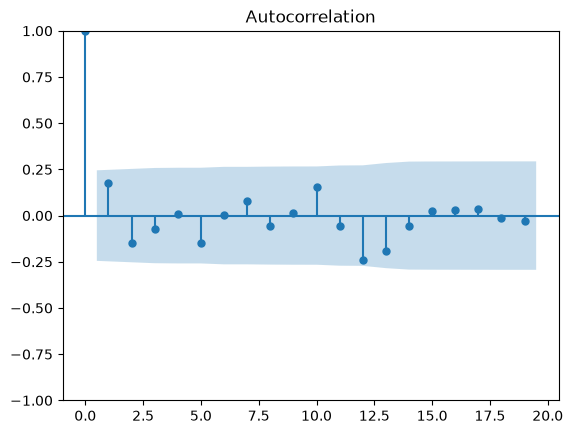

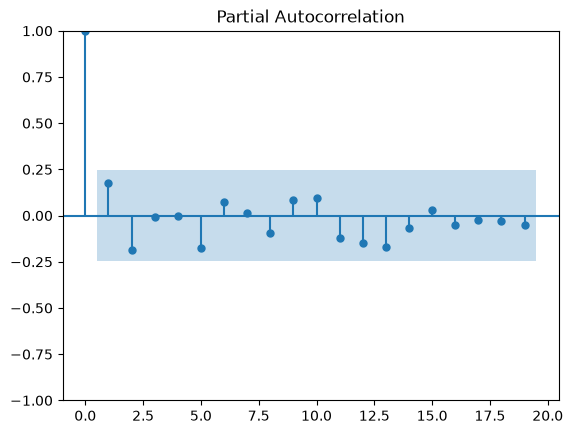

In [6]:

mean_arrival_delay_df = pd.DataFrame(departure_arrival_wo_duplicates_df[MEAN_DELAY_AT_ARRIVAL_KEY])
# mean_arrival_delay_df['Months'] = pd.to_datetime(departure_arrival_wo_duplicates_df[DATE_KEY]).dt.month
# print(mean_arrival_delay_df.head())

nb_samples = len(mean_arrival_delay_df)
print(nb_samples)
index_train_test = int(nb_samples*0.8)
predicted_samples = nb_samples - index_train_test
train_set = mean_arrival_delay_df[:index_train_test]

# don't even look at it
test_set = mean_arrival_delay_df[index_train_test:]

#ADFullerResult
augmented_dickey_fuller_test_result = adfuller(train_set, regression='ct', autolag='AIC', result_object=True)
print(augmented_dickey_fuller_test_result)

#look for autocorrelation of a reasonnable season
fig_acf = plot_acf(train_set)
fig_pacf = plot_pacf(train_set)

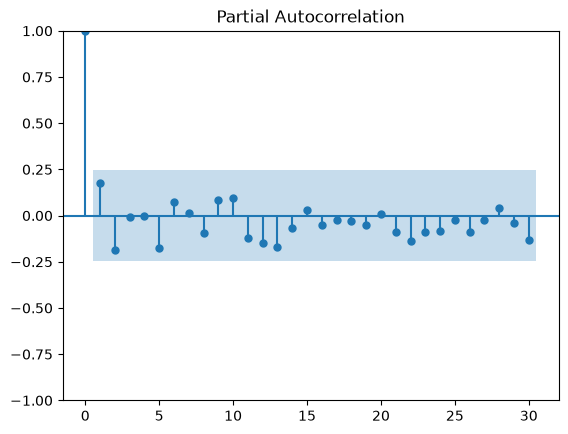

In [7]:

fig_pacf_lag = plot_pacf(train_set, lags=30)

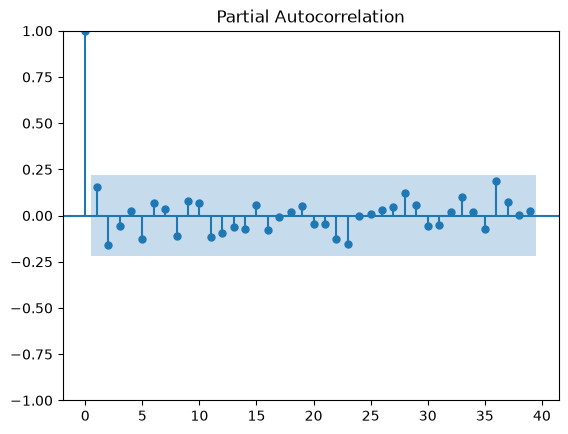

In [8]:
fig_pacf_lag = plot_pacf(mean_arrival_delay_df, lags=int(len(mean_arrival_delay_df)/2) - 1)

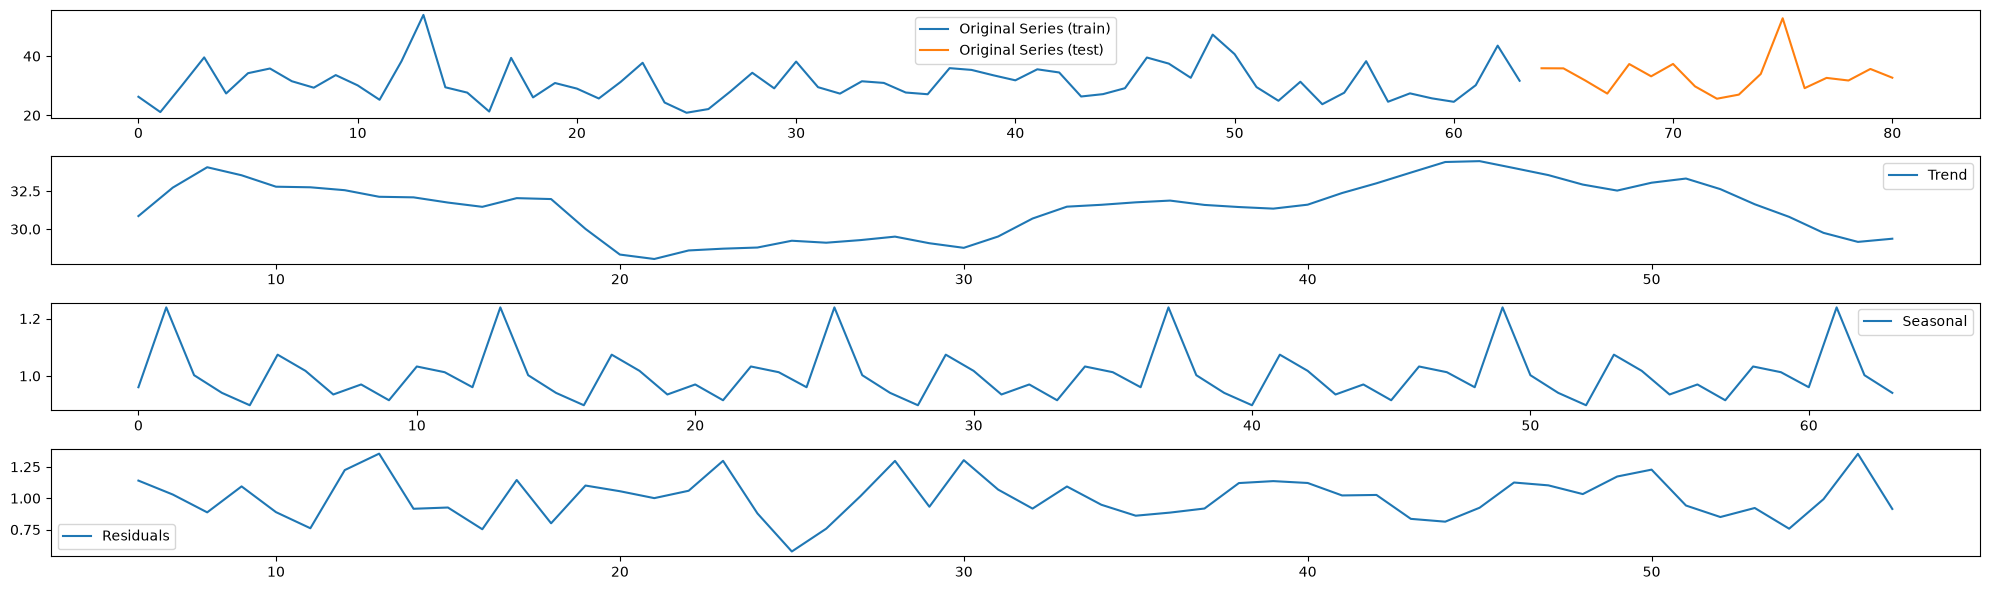

In [44]:
period_try = 12
result = seasonal_decompose(train_set, model='multiplicative', period=period_try)

trend = result.trend.dropna()
seasonal = result.seasonal.dropna()
residual = result.resid.dropna()

# Plot the decomposed components
plt.figure(figsize=(20,6))

plt.subplot(4, 1, 1)
plt.plot(train_set, label='Original Series (train)')
plt.plot(test_set, label='Original Series (test)')
plt.legend()

plt.subplot(4, 1, 2)
plt.plot(trend, label='Trend')
plt.legend()

plt.subplot(4, 1, 3)
plt.plot(seasonal, label='Seasonal')
plt.legend()

plt.subplot(4, 1, 4)
plt.plot(residual, label='Residuals')
plt.legend()

plt.tight_layout()
plt.show()

In [45]:
SARIMAX_model = pm.auto_arima(train_set,
                           start_p=1, start_q=1,
                           test='adf',
                           max_p=3, max_q=3, m=period_try,
                           start_P=0, seasonal=True,
                           d=None, D=1, max_d=1, 
                           trace=True,
                           error_action='ignore',
                           suppress_warnings=True,
                           stepwise=True)

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,1,1)[12]             : AIC=inf, Time=0.12 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=403.403, Time=0.00 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=384.338, Time=0.02 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=inf, Time=0.07 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=401.745, Time=0.01 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=376.611, Time=0.07 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=378.474, Time=0.11 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=379.764, Time=0.06 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=379.938, Time=0.05 sec
 ARIMA(2,1,0)(2,1,0)[12]             : AIC=373.615, Time=0.08 sec
 ARIMA(2,1,0)(1,1,0)[12]             : AIC=379.420, Time=0.03 sec
 ARIMA(2,1,0)(2,1,1)[12]             : AIC=375.487, Time=0.17 sec
 ARIMA(2,1,0)(1,1,1)[12]             : AIC=375.535, Time=0.10 sec
 ARIMA(3,1,0)(2,1,0)[12]             : AIC=369.595, Time=0.07 sec
 ARIMA(3,1,0)(1,1,0)[12]             : AI

In [46]:
prediction_sarimax = pd.DataFrame(SARIMAX_model.predict(n_periods=predicted_samples), index=test_set.index)
prediction_sarimax.columns = ['predicted_delay']
prediction_sarimax

,predicted_delay
64,34.460967
65,34.982119
66,44.094697
67,32.787051
68,30.793414
69,34.247789
70,39.549606
71,36.300286
72,33.450382
73,44.497816


In [47]:
arima_model = pm.auto_arima(train_set, start_p=0, d=0, start_q=0, max_p=5, max_d=1, max_q=5, 
                            start_P=0, D=1, start_Q=0, max_P=5, max_D=5, max_Q=5, m=period_try, 
                            seasonal=True, error_action='warn', trace=True, supress_warnings=True, stepwise=True, random_state=20, n_fits=50)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=394.146, Time=0.01 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=372.345, Time=0.04 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=inf, Time=0.10 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=392.167, Time=0.00 sec
 ARIMA(1,0,0)(0,1,0)[12] intercept   : AIC=391.932, Time=0.01 sec
 ARIMA(1,0,0)(2,1,0)[12] intercept   : AIC=362.674, Time=0.11 sec
 ARIMA(1,0,0)(3,1,0)[12] intercept   : AIC=364.341, Time=0.23 sec
 ARIMA(1,0,0)(2,1,1)[12] intercept   : AIC=364.318, Time=0.18 sec
 ARIMA(1,0,0)(1,1,1)[12] intercept   : AIC=366.507, Time=0.08 sec
 ARIMA(1,0,0)(3,1,1)[12] intercept   : AIC=366.306, Time=0.50 sec
 ARIMA(0,0,0)(2,1,0)[12] intercept   : AIC=362.318, Time=0.08 sec
 ARIMA(0,0,0)(1,1,0)[12] intercept   : AIC=373.343, Time=0.02 sec
 ARIMA(0,0,0)(3,1,0)[12] intercept   : AIC=364.175, Time=0.12 sec
 ARIMA(0,0,0)(2,1,1)[12] intercept   : AIC=364.161, Time=0.10 sec
 ARIMA(0,0,0)(1,1,1)[12] intercept   

In [48]:
arima_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                      
===========================================================================================
Dep. Variable:                                   y   No. Observations:                   64
Model:             SARIMAX(0, 0, 1)x(2, 1, [], 12)   Log Likelihood                -176.260
Date:                             Mon, 26 Oct 2026   AIC                            360.520
Time:                                     10:39:12   BIC                            368.325
Sample:                                          0   HQIC                           363.512
                                              - 64                                         
Covariance Type:                               opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2391      0.163      1.468      0.142      -0.080       0.558
ar.S.L12      -0.9625      0.120     -8.052      0.000      -1.197      -0.728
ar.S.L24      -0.5351      0.113     -4.727      0.000      -0.757      -0.313
sigma2        39.2245      8.477      4.627      0.000      22.609      55.840
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):                 6.90
Prob(Q):                              0.91   Prob(JB):                         0.03
Heteroskedasticity (H):               0.76   Skew:                             0.87
Prob(H) (two-sided):                  0.59   Kurtosis:                         3.42
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [49]:
prediction_arima = pd.DataFrame(arima_model.predict(n_periods=predicted_samples), index=test_set.index)
prediction_arima.columns = ['predicted_delay']
prediction_arima

,predicted_delay
64,32.373448
65,31.938053
66,36.032533
67,28.079385
68,27.658036
69,30.232152
70,34.471714
71,31.791689
72,29.389899
73,40.557156


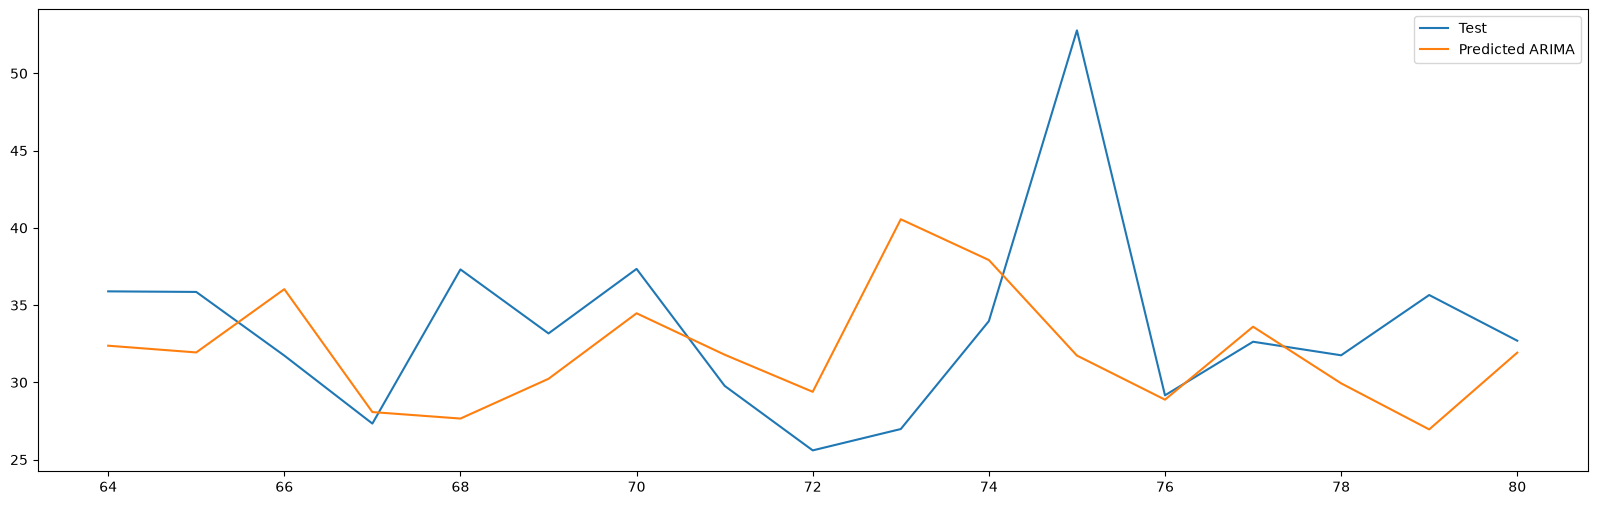

In [50]:

# Plot the decomposed components
plt.figure(figsize=(20,6))

# plt.plot(train_set, label='Training')
plt.plot(test_set, label='Test')
plt.plot(prediction_arima, label='Predicted ARIMA')
# plt.plot(prediction_sarimax, label='Predicted SARIMAX')
plt.legend()